# OULAD exploration — version 2

## Goal

Understand what each table and chart tells us, using the **saved cleaned dataset**. Every result below states what is counted, which records are included, and how to read the numbers. The earlier notebooks remain unchanged.

Read one numbered section at a time. Code calculates the results; the visible titles and notes explain them.

**Words used throughout:**

- **Student:** one person identified by `id_student`.
- **Enrollment:** one student taking one course run. A person can have several enrollments.
- **Assessment definition:** one assignment or exam offered by a course run.
- **Assessment result:** one student's record for one assessment.
- **Activity record:** a student's interaction with a resource on a day. `sum_click` tells us how many clicks it contains.
- **Course run / presentation:** one offering of a course, such as `AAA 2013J`.

## Setup and source

Main results use `data/processed/oulad/`. Raw comparisons are explicitly labeled and use `data/raw/oulad/`. The data covers course runs in 2013–2014. Cleaning rules and every changed/excluded record are in the [cleaning log](../docs/data-cleaning-log.md). [Original field definitions](https://research.stem.open.ac.uk/ouanalyse/open-dataset-more/).

To rebuild cleaned files, run `uv run --with duckdb==1.5.6 python -m src.data.cleaner` from the project folder. Notebook tools are in the project's `dev` dependency group.

**Important limits:** missing means unknown, not zero. An excluded date is not replaced with a guessed date. Clicks are not study hours. Differences between groups do not prove what caused a result.

### 1. Load the cleaned tables

**Question:** Which files are we working with?

The table below includes all seven files. The activity file is loaded later in chunks because it contains over ten million rows. “Rows” means different things in different files; the last column explains each one.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'src/data/cleaner.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.cleaner import load_clean_table
CLEAN = ROOT / 'data/processed/oulad'
RAW = ROOT / 'data/raw/oulad'
manifest = json.loads((CLEAN / 'manifest.json').read_text())
tables = {name: load_clean_table(name, CLEAN) for name in manifest['tables'] if name != 'studentVle'}
courses, assessments, vle = tables['courses'], tables['assessments'], tables['vle']
student_info = tables['studentInfo']
registration = tables['studentRegistration']
student_assessment = tables['studentAssessment']

BLUE, ORANGE, GREY = '#356C9A', '#C97930', '#777E85'
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.titlesize': 14, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)

def percent_text(value, digits=1):
    threshold = 10 ** (-digits)
    if 0 < value < threshold:
        return f'<{threshold:.{digits}f}%'
    return f'{value:.{digits}f}%'

def show_table(frame, title, note, formats=None):
    display(Markdown(f'**{title}**\n\n{note}'))
    style = frame.style.hide(axis='index').format(formats or {}, na_rep='Not available')
    style = style.set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'left'), ('font-weight', '600'),
                                    ('padding', '9px'), ('background-color', '#F0F3F5'), ('white-space', 'normal')]},
        {'selector': 'td', 'props': [('padding', '8px 9px'), ('text-align', 'left'),
                                    ('white-space', 'normal'), ('vertical-align', 'top')]},
        {'selector': 'table', 'props': [('border-collapse', 'collapse'), ('width', '100%')]}
    ])
    display(style)

def chart_note(fig, text, source, bottom=0.20):
    fig.text(0.02, 0.045, text, fontsize=10, va='bottom', ha='left')
    fig.text(0.02, 0.01, f'Source: {source}', fontsize=9, color='#59626A', va='bottom')
    fig.tight_layout(rect=(0, bottom, 1, 0.96))

row_meanings = {
    'courses': 'One offering of a course',
    'assessments': 'One assignment/exam definition',
    'vle': 'One online resource in a course run',
    'studentInfo': 'One student enrollment in a course run',
    'studentRegistration': 'Registration dates for one enrollment',
    'studentAssessment': "One student's record for one assessment",
    'studentVle': 'One student/resource/day activity record; it can contain several clicks',
}
file_overview = pd.DataFrame([
    {'File': name + '.csv', 'Raw rows': data['raw_rows'], 'Cleaned rows': data['clean_rows'],
     'What one row means': row_meanings[name]}
    for name, data in manifest['tables'].items()
])
show_table(file_overview, 'Dataset files: original versus cleaned row counts',
           'Only the activity file lost usable rows. The original excluded records are saved separately.',
           {'Raw rows': '{:,.0f}', 'Cleaned rows': '{:,.0f}'})
display(Markdown(f"**Cleaning snapshot:** {manifest['completed_at']}. "
                 f"The activity exclusions contain {manifest['vle_audit']['rejected_clicks']:,} clicks; "
                 'an activity row and a click are different units.'))

**Dataset files: original versus cleaned row counts**

Only the activity file lost usable rows. The original excluded records are saved separately.

File,Raw rows,Cleaned rows,What one row means
courses.csv,22,22,One offering of a course
assessments.csv,206,206,One assignment/exam definition
vle.csv,"6,364","6,364",One online resource in a course run
studentInfo.csv,"32,593","32,593",One student enrollment in a course run
studentRegistration.csv,"32,593","32,593",Registration dates for one enrollment
studentAssessment.csv,"173,912","173,912",One student's record for one assessment
studentVle.csv,"10,655,280","10,626,266",One student/resource/day activity record; it can contain several clicks


**Cleaning snapshot:** 2026-10-13T08:36:32.164615+00:00. The activity exclusions contain 97,854 clicks; an activity row and a click are different units.

### 2. What is missing, and do the files connect?

**Question:** Which information is unknown?

A missing score is not a score of zero. A missing withdrawal date is often expected because the student stayed enrolled. Unknown planned weeks mean we cannot use those fields as a complete schedule.

In [2]:
missing_rows = []
for name, table in manifest['tables'].items():
    for column, count in table['missing_after'].items():
        if count:
            missing_rows.append({'File': name, 'Field': column, 'Unknown values': count,
                                 'Rows in that file': table['clean_rows'],
                                 'Unknown share (%)': 100 * count / table['clean_rows']})
missing_summary = pd.DataFrame(missing_rows)
show_table(missing_summary, 'Missing values in the cleaned files',
           'Each percentage uses the row count of its own file. The same row may have more than one missing field.',
           {'Unknown values': '{:,.0f}', 'Rows in that file': '{:,.0f}', 'Unknown share (%)': lambda value: percent_text(value, 2)})
validation = pd.DataFrame(json.loads((CLEAN / 'validation_report.json').read_text()))
show_table(pd.DataFrame({'Saved cleaning checks': [len(validation)],
                        'Passed': [int(validation['passed'].sum())],
                        'Failed': [int((~validation['passed']).sum())]}),
           'Saved full-dataset cleaning checks',
           'These checks include value ranges, row identities, links between files, and the cleaned date rules. '
           'They do not establish facts the original source did not record.')

**Missing values in the cleaned files**

Each percentage uses the row count of its own file. The same row may have more than one missing field.

File,Field,Unknown values,Rows in that file,Unknown share (%)
assessments,date,11,206,5.34%
vle,week_from,"5,243","6,364",82.39%
vle,week_to,"5,243","6,364",82.39%
studentInfo,imd_band,"1,111","32,593",3.41%
studentRegistration,date_registration,45,"32,593",0.14%
studentRegistration,date_unregistration,"22,532","32,593",69.13%
studentAssessment,date_submitted,598,"173,912",0.34%
studentAssessment,score,173,"173,912",0.10%


**Saved full-dataset cleaning checks**

These checks include value ranges, row identities, links between files, and the cleaned date rules. They do not establish facts the original source did not record.

Saved cleaning checks,Passed,Failed
104,104,0


**How to read this chart:** each bar represents one field. Its length is the percentage of that file's rows with an unknown value. The label also gives the count. These percentages are not parts of a single total.

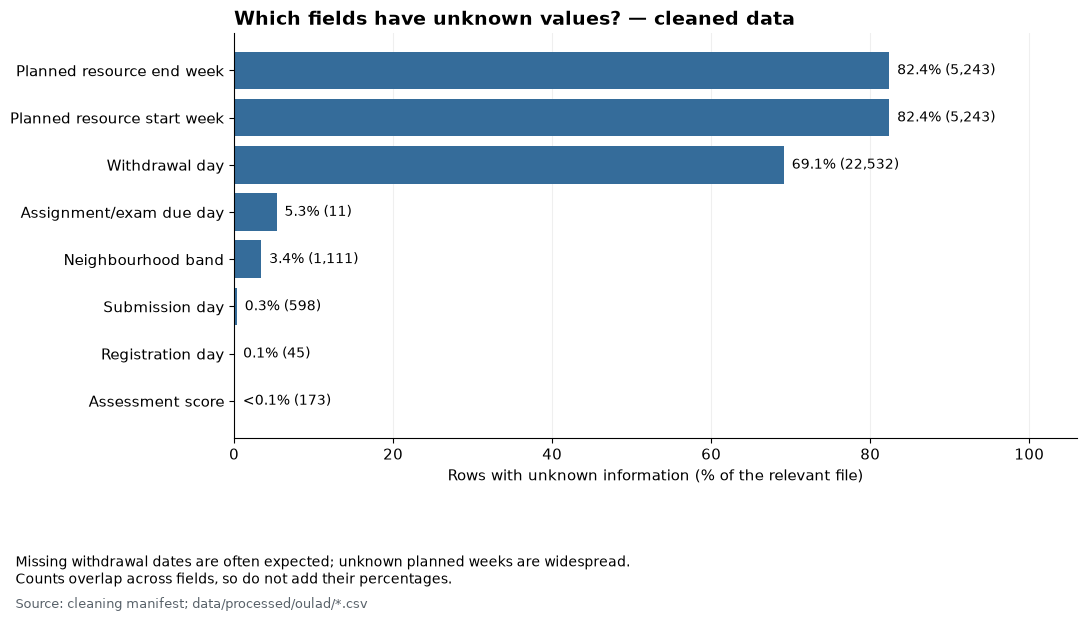

In [3]:
missing_plot = missing_summary.sort_values('Unknown share (%)').copy()
fig, ax = plt.subplots(figsize=(11, 6.5))
field_labels = {'week_from': 'Planned resource start week', 'week_to': 'Planned resource end week',
                'date_unregistration': 'Withdrawal day', 'date': 'Assignment/exam due day',
                'imd_band': 'Neighbourhood band', 'date_submitted': 'Submission day',
                'date_registration': 'Registration day', 'score': 'Assessment score'}
labels = missing_plot['Field'].map(field_labels)
bars = ax.barh(labels, missing_plot['Unknown share (%)'], color=BLUE)
for bar, (_, row) in zip(bars, missing_plot.iterrows()):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f"{percent_text(row['Unknown share (%)'])} ({row['Unknown values']:,})", va='center', fontsize=10)
ax.set_xlim(0, 106)
ax.set_xlabel('Rows with unknown information (% of the relevant file)')
ax.set_title('Which fields have unknown values? — cleaned data', loc='left')
ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
chart_note(fig, 'Missing withdrawal dates are often expected; unknown planned weeks are widespread.\nCounts overlap across fields, so do not add their percentages.',
           'cleaning manifest; data/processed/oulad/*.csv', bottom=.18)
plt.show()

**Question:** Can we safely connect a result to its course and student?

An enrollment needs all three fields—course, run, and student—to identify it. Repeated student IDs alone are expected when someone takes multiple courses.

In [4]:
course_keys = ['code_module', 'code_presentation']
enrollment_keys = course_keys + ['id_student']
assessment_links = student_assessment.merge(
    assessments[['id_assessment', *course_keys]], on='id_assessment', how='left', validate='many_to_one'
).merge(student_info[enrollment_keys], on=enrollment_keys, how='left', indicator=True, validate='many_to_one')
course_match = student_info.merge(courses[course_keys], on=course_keys, how='left', indicator=True)
registration_match = student_info.merge(registration[enrollment_keys], on=enrollment_keys, how='left', indicator=True)
connection_checks = pd.DataFrame([
    {'Check': 'Repeated enrollment identities (same course, run and student)', 'Problem records': int(student_info.duplicated(enrollment_keys).sum())},
    {'Check': 'Enrollment has no matching course run', 'Problem records': int(course_match['_merge'].eq('left_only').sum())},
    {'Check': 'Enrollment has no matching registration record', 'Problem records': int(registration_match['_merge'].eq('left_only').sum())},
    {'Check': 'Assessment result has no matching student enrollment', 'Problem records': int(assessment_links['_merge'].eq('left_only').sum())},
])
connection_checks['Result'] = np.where(connection_checks['Problem records'].eq(0), 'Passed', 'Needs review')
show_table(connection_checks, 'Links between the small tables',
           'Zero problem records means every row passed this particular check.', {'Problem records': '{:,.0f}'})
assert connection_checks['Problem records'].eq(0).all()

**Links between the small tables**

Zero problem records means every row passed this particular check.

Check,Problem records,Result
"Repeated enrollment identities (same course, run and student)",0,Passed
Enrollment has no matching course run,0,Passed
Enrollment has no matching registration record,0,Passed
Assessment result has no matching student enrollment,0,Passed


### 3. How many people and course enrollments are there?

**Question:** Why do we have more enrollment rows than unique students?

Each row in `studentInfo` is one course enrollment. The same person can appear in several rows.

In [5]:
unique_students = int(student_info['id_student'].nunique())
show_table(pd.DataFrame({'Measure': ['Distinct students', 'Course enrollments', 'Courses', 'Course runs'],
                        'Count': [unique_students, len(student_info), courses['code_module'].nunique(), len(courses)]}),
           'Population and course structure', 'These are different units; they should not be added together.', {'Count': '{:,.0f}'})
repetition = student_info['id_student'].value_counts().value_counts().sort_index()
repeat_table = pd.DataFrame({'Enrollments per person': repetition.index, 'Distinct students': repetition.values})
repeat_table['Share of students (%)'] = repeat_table['Distinct students'] / unique_students * 100
show_table(repeat_table, 'How many course enrollments each person has',
           f'Percentages are out of {unique_students:,} distinct students. A person is counted in exactly one row here.',
           {'Distinct students': '{:,.0f}', 'Share of students (%)': lambda value: percent_text(value, 1)})
assert repeat_table['Distinct students'].sum() == unique_students
assert (repeat_table['Enrollments per person'] * repeat_table['Distinct students']).sum() == len(student_info)

**Population and course structure**

These are different units; they should not be added together.

Measure,Count
Distinct students,"28,785"
Course enrollments,"32,593"
Courses,7
Course runs,22


**How many course enrollments each person has**

Percentages are out of 28,785 distinct students. A person is counted in exactly one row here.

Enrollments per person,Distinct students,Share of students (%)
1,"25,247",87.7%
2,"3,293",11.4%
3,221,0.8%
4,23,<0.1%
5,1,<0.1%


### 4. What final results did students get?

**Question:** How many enrollments ended in each outcome?

**Distinction** means a top-level result; **Pass** means a regular pass; **Fail** means the course was failed; **Withdrawn** means the student left the course. The categories are separate, so “Pass” below excludes Distinction.

**Final course outcomes across all enrollments**

Each enrollment is counted once. Percentages use all 32,593 enrollments; they are not percentages of unique people.

Final course result,Enrollment count,Share of all enrollments (%)
Distinction,"3,024",9.28%
Pass,"12,361",37.93%
Fail,"7,052",21.64%
Withdrawn,"10,156",31.16%


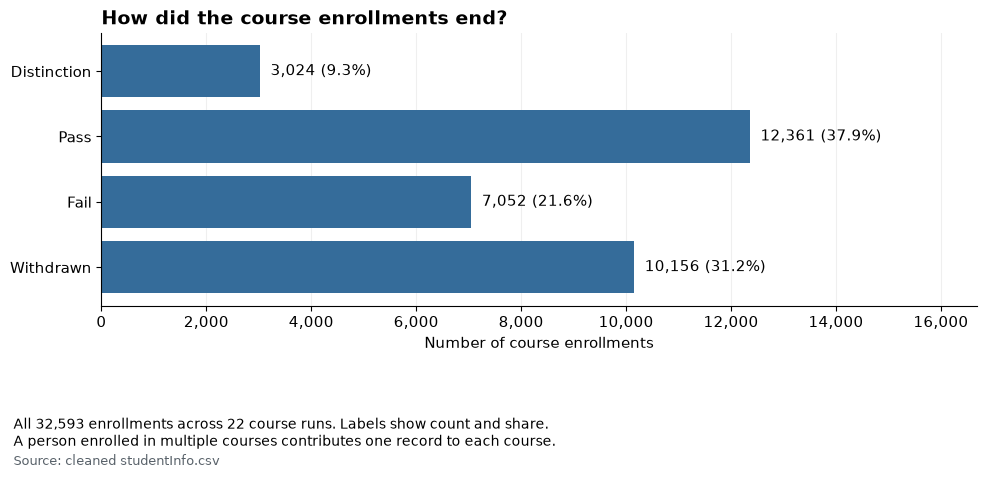

In [6]:
outcome_order = ['Distinction', 'Pass', 'Fail', 'Withdrawn']
outcome_counts = student_info['final_result'].value_counts().reindex(outcome_order)
outcomes = pd.DataFrame({'Final course result': outcome_order, 'Enrollment count': outcome_counts.values})
outcomes['Share of all enrollments (%)'] = outcomes['Enrollment count'] / len(student_info) * 100
show_table(outcomes, 'Final course outcomes across all enrollments',
           f'Each enrollment is counted once. Percentages use all {len(student_info):,} enrollments; they are not percentages of unique people.',
           {'Enrollment count': '{:,.0f}', 'Share of all enrollments (%)': lambda value: percent_text(value, 2)})
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(outcomes['Final course result'], outcomes['Enrollment count'], color=BLUE)
ax.invert_yaxis()
for bar, (_, row) in zip(bars, outcomes.iterrows()):
    ax.text(bar.get_width() + 200, bar.get_y() + bar.get_height()/2,
            f"{row['Enrollment count']:,} ({row['Share of all enrollments (%)']:.1f}%)", va='center')
ax.set_xlim(0, outcomes['Enrollment count'].max() * 1.35)
ax.set_xlabel('Number of course enrollments')
ax.set_title('How did the course enrollments end?', loc='left')
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value:,.0f}'))
ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
chart_note(fig, f'All {len(student_info):,} enrollments across 22 course runs. Labels show count and share.\nA person enrolled in multiple courses contributes one record to each course.',
           'cleaned studentInfo.csv', bottom=.21)
plt.show()

**Question:** Do results differ between course runs?

Every outcome cell below reads **number (percentage of that row's enrollments)**. “Total enrollments” is the denominator. `2013B` and `2013J` are different runs in the same year; B and J identify February and October offerings.

In [7]:
by_run_counts = pd.crosstab([student_info['code_module'], student_info['code_presentation']], student_info['final_result']).reindex(columns=outcome_order)
by_run_percent = by_run_counts.div(by_run_counts.sum(axis=1), axis=0) * 100
by_run = by_run_counts.astype('string')
for outcome in outcome_order:
    by_run[outcome] = by_run_counts[outcome].map(lambda value: f'{value:,}') + ' (' + by_run_percent[outcome].map(lambda value: f'{value:.1f}%') + ')'
by_run['Total enrollments'] = by_run_counts.sum(axis=1)
by_run = by_run.reset_index().rename(columns={'code_module': 'Course', 'code_presentation': 'Course run'})
show_table(by_run, 'Final outcomes for each course run',
           'Percentages compare students within the same row, not across the whole dataset.', {'Total enrollments': '{:,.0f}'})
aaa = by_run_counts.loc[('AAA', '2013J')]
display(Markdown(f"**Example:** AAA 2013J has **{aaa.sum():,} enrollments**. "
                 f"**{aaa['Distinction']:,} ({by_run_percent.loc[('AAA','2013J'),'Distinction']:.1f}%)** received a Distinction. "
                 'The rows differ, so a single overall percentage does not describe every course run.'))

**Final outcomes for each course run**

Percentages compare students within the same row, not across the whole dataset.

Course,Course run,Distinction,Pass,Fail,Withdrawn,Total enrollments
AAA,2013J,20 (5.2%),258 (67.4%),45 (11.7%),60 (15.7%),383
AAA,2014J,24 (6.6%),229 (62.7%),46 (12.6%),66 (18.1%),365
BBB,2013B,155 (8.8%),648 (36.7%),459 (26.0%),505 (28.6%),"1,767"
BBB,2013J,176 (7.9%),896 (40.1%),521 (23.3%),644 (28.8%),"2,237"
BBB,2014B,166 (10.3%),561 (34.8%),396 (24.6%),490 (30.4%),"1,613"
BBB,2014J,180 (7.9%),972 (42.4%),391 (17.1%),749 (32.7%),"2,292"
CCC,2014B,192 (9.9%),471 (24.3%),375 (19.4%),898 (46.4%),"1,936"
CCC,2014J,306 (12.2%),709 (28.4%),406 (16.3%),"1,077 (43.1%)","2,498"
DDD,2013B,54 (4.1%),456 (35.0%),361 (27.7%),432 (33.2%),"1,303"
DDD,2013J,98 (5.1%),731 (37.7%),428 (22.1%),681 (35.1%),"1,938"


**Example:** AAA 2013J has **383 enrollments**. **20 (5.2%)** received a Distinction. The rows differ, so a single overall percentage does not describe every course run.

### 5. When did students register or leave?

**Question:** What do the dates mean?

Dates are measured in days relative to the course start. **−57 = 57 days before the course started. +27 = 27 days after it started.** Missing withdrawal dates are not treated as day zero.

In the summary: average is the mean; the middle value is the median; standard deviation describes how spread out the dates are. The 25% and 75% rows are checkpoints in the sorted known dates.

In [8]:
date_describe = registration[['date_registration', 'date_unregistration']].describe()
summary_labels = {
    'count': 'Known dates (count)', 'mean': 'Average date (mean, days)',
    'std': 'Spread of dates (standard deviation, days)', 'min': 'Earliest known date (days)',
    '25%': '25% of known dates are at or before this day',
    '50%': 'Half of known dates are at or before this day (median)',
    '75%': '75% of known dates are at or before this day', 'max': 'Latest known date (days)',
}
date_table = date_describe.rename(index=summary_labels, columns={
    'date_registration': 'Registration: days from course start',
    'date_unregistration': 'Withdrawal: days from course start'}).reset_index(names='Meaning of this row')
for column in date_table.columns[1:]:
    date_table[column] = [f'{value:,.0f}' if idx == 0 else f'{value:+.2f}' for idx, value in enumerate(date_table[column])]
show_table(date_table, 'Registration and withdrawal dates — cleaned data',
           'Counts use known dates only. Negative means before the course start; positive means after it.')
median_registration = float(registration['date_registration'].median())
display(Markdown(f'**What we learned:** the median registration was **{abs(median_registration):.0f} days before** the course start. '
                 'Eleven conflicting withdrawal dates were excluded by the cleaning rules. Their originals are in the cleaning log.'))

**Registration and withdrawal dates — cleaned data**

Counts use known dates only. Negative means before the course start; positive means after it.

Meaning of this row,Registration: days from course start,Withdrawal: days from course start
Known dates (count),"32,548","10,061"
"Average date (mean, days)",-69.41,+49.79
"Spread of dates (standard deviation, days)",+49.26,+82.29
Earliest known date (days),-322.00,-317.00
25% of known dates are at or before this day,-100.00,-2.00
Half of known dates are at or before this day (median),-57.00,+27.00
75% of known dates are at or before this day,-29.00,+109.00
Latest known date (days),+167.00,+242.00


**What we learned:** the median registration was **57 days before** the course start. Eleven conflicting withdrawal dates were excluded by the cleaning rules. Their originals are in the cleaning log.

**How to read this chart:** each bar counts enrollments registered during a range of days. The dashed line marks the course start. Most registrations appear to its left, meaning before the course began.

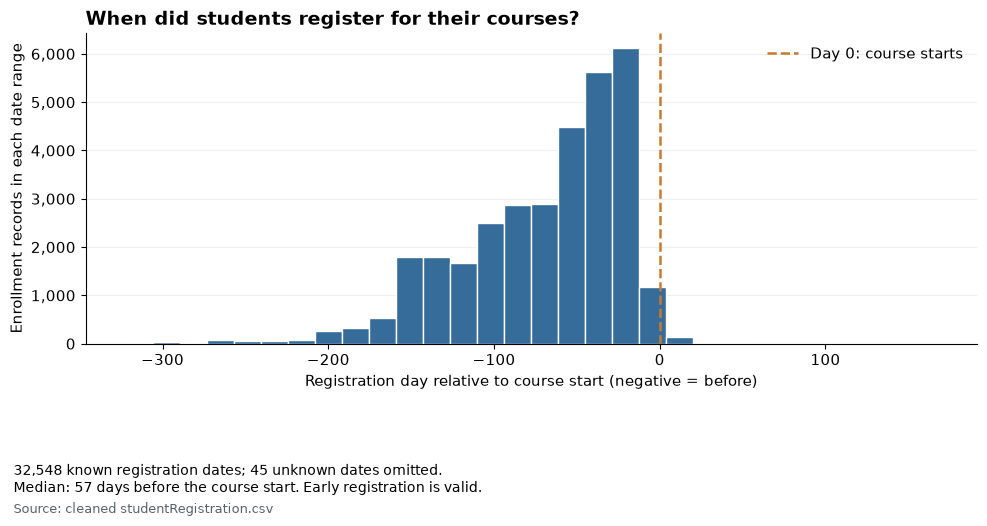

In [9]:
known_registrations = registration['date_registration'].dropna().astype(int)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(known_registrations, bins=30, color=BLUE, edgecolor='white')
ax.axvline(0, color=ORANGE, linestyle='--', linewidth=1.8, label='Day 0: course starts')
ax.set_xlabel('Registration day relative to course start (negative = before)')
ax.set_ylabel('Enrollment records in each date range')
ax.set_title('When did students register for their courses?', loc='left')
ax.legend(loc='upper right', frameon=False)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value:,.0f}'))
ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
chart_note(fig, f'{len(known_registrations):,} known registration dates; {registration.date_registration.isna().sum():,} unknown dates omitted.\nMedian: {abs(median_registration):.0f} days before the course start. Early registration is valid.',
           'cleaned studentRegistration.csv', bottom=.21)
plt.show()

### 6. Were assessments submitted on time, and what were their scores?

**Question:** What did `True`, `False`, and `NaN` mean in the old output?

- **On time:** submission day is on or before the deadline.
- **Late:** submission day is after the deadline.
- **Due date unknown:** the deadline is missing, so lateness cannot be decided.
- **Submission date unavailable:** cleaning excluded the submission date, so timing cannot be decided.
- **Both dates unavailable:** neither date is usable.
- **Carried-over result (not timed):** the mark came from an earlier course run; it is not a new submission to time against this run's deadline.

The new results can differ from the old screenshots: this version uses cleaned dates and shows carried-over marks separately. Timing uses dates only, even if a score is missing.

In [10]:
assessment_rows = student_assessment.merge(assessments, on='id_assessment', how='left', validate='many_to_one')
status_order = ['On time', 'Late', 'Due date unknown', 'Submission date unavailable',
                'Both dates unavailable', 'Carried-over result (not timed)']
status = pd.Series('On time', index=assessment_rows.index, dtype='string')
status.loc[assessment_rows['date_submitted'].gt(assessment_rows['date']).fillna(False)] = 'Late'
status.loc[assessment_rows['date'].isna()] = 'Due date unknown'
status.loc[assessment_rows['date_submitted'].isna()] = 'Submission date unavailable'
status.loc[assessment_rows['date'].isna() & assessment_rows['date_submitted'].isna()] = 'Both dates unavailable'
status.loc[assessment_rows['is_banked'].eq(1)] = 'Carried-over result (not timed)'
assessment_rows['Timing status'] = status
record_counts = status.value_counts().reindex(status_order, fill_value=0)
timing_counts = pd.DataFrame({'Timing status': status_order, 'Assessment result records': record_counts.values})
timing_counts['Share of all result records (%)'] = timing_counts['Assessment result records'] / len(assessment_rows) * 100
show_table(timing_counts, 'How the assessment result records are classified',
           f'Each of the {len(assessment_rows):,} result records appears in exactly one category. Percentages use all result records, including carried-over marks.',
           {'Assessment result records': '{:,.0f}', 'Share of all result records (%)': lambda value: percent_text(value, 2)})
assert timing_counts['Assessment result records'].sum() == len(assessment_rows)
known_timing_total = int(record_counts['On time'] + record_counts['Late'])
late_share = 100 * record_counts['Late'] / known_timing_total
display(Markdown(f"**Among new results with usable submission and due dates:** "
                 f"**{record_counts['Late']:,} of {known_timing_total:,} ({late_share:.1f}%)** were late. "
                 'Unknown-date records and carried-over results are excluded from this particular percentage.'))

**How the assessment result records are classified**

Each of the 173,912 result records appears in exactly one category. Percentages use all result records, including carried-over marks.

Timing status,Assessment result records,Share of all result records (%)
On time,"119,515",68.72%
Late,"49,030",28.19%
Due date unknown,"2,860",1.64%
Submission date unavailable,593,0.34%
Both dates unavailable,5,<0.01%
Carried-over result (not timed),"1,909",1.10%


**Among new results with usable submission and due dates:** **49,030 of 168,545 (29.1%)** were late. Unknown-date records and carried-over results are excluded from this particular percentage.

**How to read this chart:** bar length shows assessment-result records. Labels give both count and share of all records. Grey bars show categories that cannot be used as new on-time/late submissions.

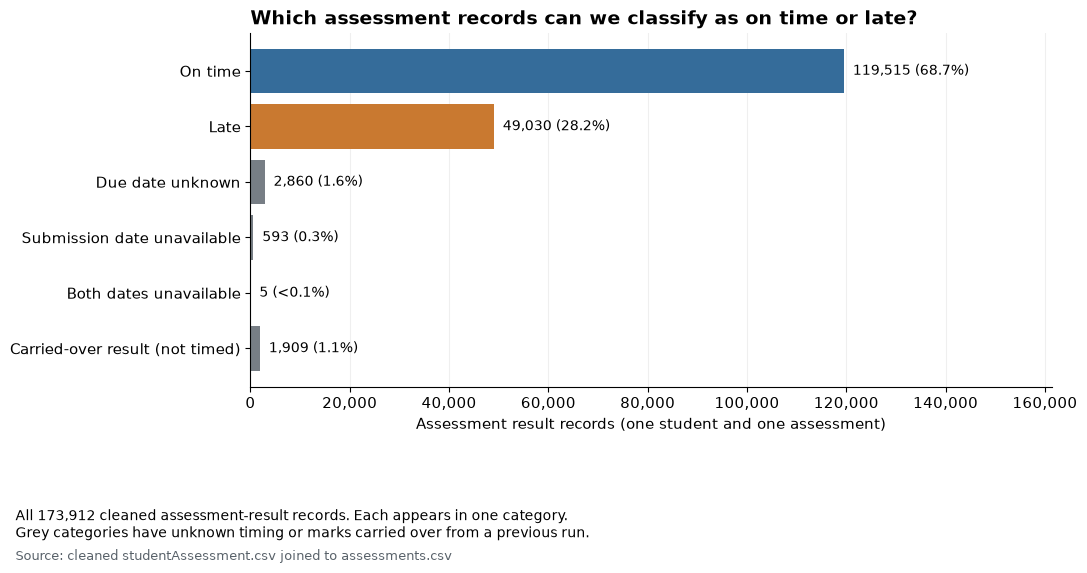

In [11]:
fig, ax = plt.subplots(figsize=(11, 6))
colors = [BLUE, ORANGE, GREY, GREY, GREY, GREY]
bars = ax.barh(timing_counts['Timing status'], timing_counts['Assessment result records'], color=colors)
ax.invert_yaxis()
for bar, (_, row) in zip(bars, timing_counts.iterrows()):
    ax.text(bar.get_width() + 1800, bar.get_y() + bar.get_height()/2,
            f"{row['Assessment result records']:,} ({percent_text(row['Share of all result records (%)'])})", va='center', fontsize=10)
ax.set_xlim(0, record_counts.max() * 1.35)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value:,.0f}'))
ax.set_xlabel('Assessment result records (one student and one assessment)')
ax.set_title('Which assessment records can we classify as on time or late?', loc='left')
ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
chart_note(fig, f'All {len(assessment_rows):,} cleaned assessment-result records. Each appears in one category.\nGrey categories have unknown timing or marks carried over from a previous run.',
           'cleaned studentAssessment.csv joined to assessments.csv', bottom=.20)
plt.show()

**Question:** Do on-time and late records have different scores?

“Assessment records” counts rows even if their score is unknown. **Scores available** counts only rows with a recorded numeric score. The average and median use that second count. Scores are points out of 100; a median is the middle score after sorting.

In [12]:
score_groups = assessment_rows.groupby('Timing status')['score'].agg(
    records='size', known_scores='count', average_score='mean', middle_score='median'
).reindex(status_order)
score_summary = score_groups.reset_index().rename(columns={
    'records': 'Assessment records', 'known_scores': 'Scores available',
    'average_score': 'Average score /100', 'middle_score': 'Middle score (median) /100'})
show_table(score_summary, 'Scores by submission timing — cleaned results',
           'Unknown scores are excluded from averages and medians. A missing date does not make a recorded score disappear.',
           {'Assessment records': '{:,.0f}', 'Scores available': '{:,.0f}',
            'Average score /100': '{:.2f}', 'Middle score (median) /100': '{:.1f}'})
assert score_summary['Scores available'].sum() == assessment_rows['score'].notna().sum()
mean_on_time = float(score_groups.loc['On time', 'average_score'])
mean_late = float(score_groups.loc['Late', 'average_score'])
display(Markdown(f'**What we learned:** known scores average **{mean_on_time:.2f}/100 on time** and '
                 f'**{mean_late:.2f}/100 late**. This is a descriptive comparison; it does not prove that lateness caused the difference.'))

**Scores by submission timing — cleaned results**

Unknown scores are excluded from averages and medians. A missing date does not make a recorded score disappear.

Timing status,Assessment records,Scores available,Average score /100,Middle score (median) /100
On time,"119,515","119,488",76.37,80.0
Late,"49,030","48,903",75.08,80.0
Due date unknown,"2,860","2,860",67.07,68.0
Submission date unavailable,593,575,66.45,70.0
Both dates unavailable,5,5,55.00,56.0
Carried-over result (not timed),"1,909","1,908",74.35,76.0


**What we learned:** known scores average **76.37/100 on time** and **75.08/100 late**. This is a descriptive comparison; it does not prove that lateness caused the difference.

**Question:** Does the comparison change for different assessment types?

- **TMA:** tutor-marked assignment.
- **CMA:** computer-marked assessment.
- **Exam:** final exam.

The table separates type and timing status. “Share of this type” uses all result records for that assessment type, not the whole dataset.

In [13]:
type_totals = assessment_rows.groupby('assessment_type').size()
type_scores = assessment_rows.groupby(['assessment_type', 'Timing status']).agg(
    records=('score', 'size'), known_scores=('score', 'count'),
    average_score=('score', 'mean'), middle_score=('score', 'median')
).reset_index()
type_scores['Share of this type (%)'] = [100 * row.records / type_totals.loc[row.assessment_type]
                                         for row in type_scores.itertuples()]
type_scores['assessment_type'] = pd.Categorical(type_scores['assessment_type'], ['TMA', 'CMA', 'Exam'], ordered=True)
type_scores['Timing status'] = pd.Categorical(type_scores['Timing status'], status_order, ordered=True)
type_scores = type_scores.sort_values(['assessment_type', 'Timing status'])
type_score_table = type_scores.rename(columns={'assessment_type': 'Assessment type', 'records': 'Result records',
    'known_scores': 'Scores available', 'average_score': 'Average score /100', 'middle_score': 'Middle score /100'})
show_table(type_score_table, 'Assessment scores by type and timing',
           'Rows with no observed records are omitted. “Scores available” is the denominator for the average and median.',
           {'Result records': '{:,.0f}', 'Scores available': '{:,.0f}', 'Average score /100': '{:.2f}',
            'Middle score /100': '{:.1f}', 'Share of this type (%)': lambda value: percent_text(value, 2)})
exam_late_count = int(((assessment_rows['assessment_type'] == 'Exam') & (status == 'Late')).sum())
display(Markdown(f'**Exam caution:** there are **{exam_late_count} usable late exam results** in this cleaned timing comparison. '
                 'The old raw output had seven; their submission dates were excluded by the cleaning rules. '
                 'An absent late-exam row does not mean late exams had an average score of zero.'))

**Assessment scores by type and timing**

Rows with no observed records are omitted. “Scores available” is the denominator for the average and median.

Assessment type,Timing status,Result records,Scores available,Average score /100,Middle score /100,Share of this type (%)
TMA,On time,"80,522","80,495",74.11,77.0,81.81%
TMA,Late,"16,262","16,135",65.05,68.0,16.52%
TMA,Submission date unavailable,304,286,63.29,68.5,0.31%
TMA,Carried-over result (not timed),"1,338","1,337",71.95,74.0,1.36%
CMA,On time,"36,907","36,907",82.03,83.0,52.33%
CMA,Late,"32,768","32,768",80.02,81.0,46.46%
CMA,Submission date unavailable,281,281,70.01,76.0,0.40%
CMA,Carried-over result (not timed),571,571,79.96,81.0,0.81%
Exam,On time,"2,086","2,086",63.58,64.0,42.06%
Exam,Due date unknown,"2,860","2,860",67.07,68.0,57.67%


**Exam caution:** there are **0 usable late exam results** in this cleaned timing comparison. The old raw output had seven; their submission dates were excluded by the cleaning rules. An absent late-exam row does not mean late exams had an average score of zero.

**Question:** How many tests have an unknown deadline?

This table counts **assessment definitions**, not students' result records. One exam with an unknown deadline can affect hundreds of student results. That is why a small number of missing exam definitions produces thousands of unknown-timing result records.

In [14]:
definition_summary = assessments.groupby('assessment_type').agg(
    definitions=('id_assessment', 'size'), unknown_deadlines=('date', lambda values: values.isna().sum())
).reindex(['TMA', 'CMA', 'Exam']).reset_index()
definition_summary['Unknown deadlines (%)'] = definition_summary['unknown_deadlines'] / definition_summary['definitions'] * 100
show_table(definition_summary.rename(columns={'assessment_type': 'Assessment type',
    'definitions': 'Assignment/exam definitions', 'unknown_deadlines': 'Definitions with unknown deadline'}),
           'Assessment definitions and missing deadlines',
           'Percentages use the number of definitions for that type. These counts do not count students.',
           {'Assignment/exam definitions': '{:,.0f}', 'Definitions with unknown deadline': '{:,.0f}', 'Unknown deadlines (%)': lambda value: percent_text(value, 1)})

**Assessment definitions and missing deadlines**

Percentages use the number of definitions for that type. These counts do not count students.

Assessment type,Assignment/exam definitions,Definitions with unknown deadline,Unknown deadlines (%)
TMA,106,0,0.0%
CMA,76,0,0.0%
Exam,24,11,45.8%


**How to read this chart:** each panel is one assignment type. Blue means on time; orange means late. Bar length is the average recorded score out of 100. The label shows the score and how many scores were used.

Only new submissions with known usable dates and scores are compared. Exams are omitted because there are no usable late exam results in this cleaned comparison.

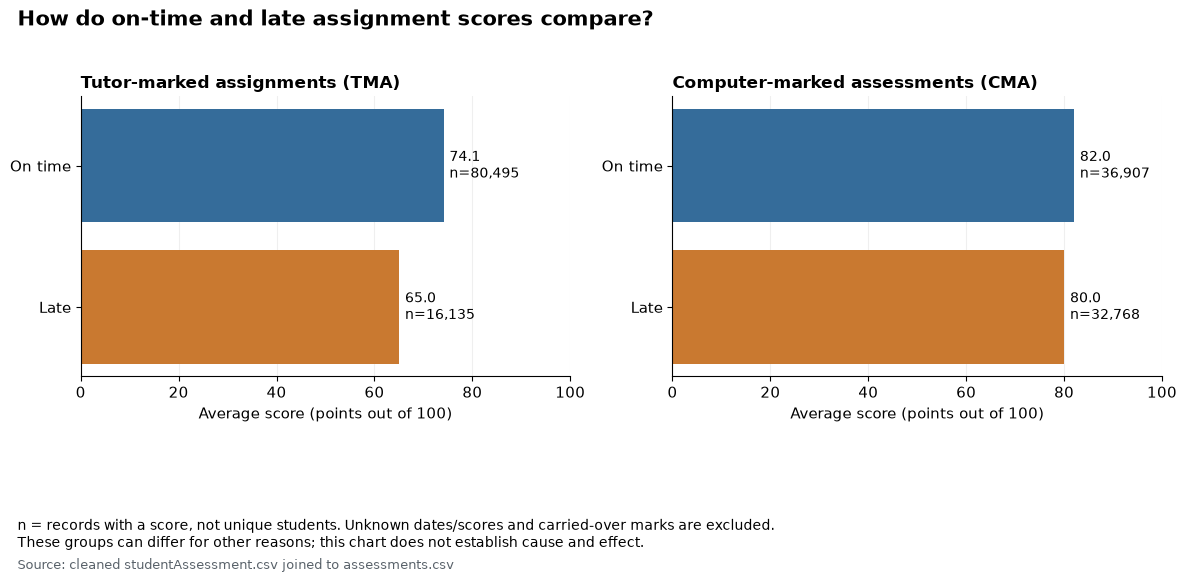

**Reading the bars:** tutor-marked scores average 74.11 on time versus 65.05 late (a 9.07-point difference). Computer-marked scores average 82.03 versus 80.02 (a 2.01-point difference). This compares observed groups; it does not establish why their results differ.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.8), sharex=True)
for ax, assessment_type, title in zip(axes, ['TMA', 'CMA'], ['Tutor-marked assignments (TMA)', 'Computer-marked assessments (CMA)']):
    rows = type_scores.loc[type_scores['assessment_type'].eq(assessment_type) & type_scores['Timing status'].isin(['On time', 'Late'])].set_index('Timing status').reindex(['On time', 'Late'])
    bars = ax.barh(['On time', 'Late'], rows['average_score'].astype(float), color=[BLUE, ORANGE])
    ax.invert_yaxis()
    for bar, (_, row) in zip(bars, rows.iterrows()):
        ax.text(bar.get_width() + 1.2, bar.get_y() + bar.get_height()/2,
                f"{row['average_score']:.1f}\nn={row['known_scores']:,}", va='center', fontsize=10)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Average score (points out of 100)')
    ax.set_title(title, fontsize=12, loc='left')
    ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
fig.suptitle('How do on-time and late assignment scores compare?', fontsize=15, weight='bold', x=.02, ha='left')
chart_note(fig, 'n = records with a score, not unique students. Unknown dates/scores and carried-over marks are excluded.\nThese groups can differ for other reasons; this chart does not establish cause and effect.',
           'cleaned studentAssessment.csv joined to assessments.csv', bottom=.24)
plt.show()
comparisons = type_scores.loc[type_scores['Timing status'].isin(['On time', 'Late'])].set_index(['assessment_type', 'Timing status'])
tma_on = float(comparisons.loc[('TMA', 'On time'), 'average_score'])
tma_late = float(comparisons.loc[('TMA', 'Late'), 'average_score'])
cma_on = float(comparisons.loc[('CMA', 'On time'), 'average_score'])
cma_late = float(comparisons.loc[('CMA', 'Late'), 'average_score'])
display(Markdown(f'**Reading the bars:** tutor-marked scores average {tma_on:.2f} on time versus {tma_late:.2f} late '
                 f'(a {tma_on - tma_late:.2f}-point difference). Computer-marked scores average '
                 f'{cma_on:.2f} versus {cma_late:.2f} (a {cma_on - cma_late:.2f}-point difference). '
                 'This compares observed groups; it does not establish why their results differ.'))

### 7. What did the timeline cleaning change?

**Question:** Which actual date values were excluded?

The rules use the recorded course/enrollment window. Conflicting submission dates are cleared but assessment scores remain. Activity after withdrawal is moved to a separate file. A record can fail more than one rule, so date cells are counted once below.

In [16]:
changes = pd.read_csv(CLEAN / 'cell_changes.csv', dtype='string', keep_default_na=False)
date_edits = changes.loc[changes['field'].isin(['date_submitted', 'date_unregistration']) & changes['before'].ne('?')]
date_changes_table = date_edits.groupby(['table', 'issue']).size().reset_index(name='Date cells cleared').rename(columns={'table': 'File', 'issue': 'Why the date is excluded'})
show_table(date_changes_table, 'Actual date conflicts handled by cleaning',
           'Each original date cell appears once; combined reasons mean that same date broke both rules.', {'Date cells cleared': '{:,.0f}'})
raw_activity_rows = manifest['vle_audit']['source_rows']
activity_partition = pd.DataFrame({'Activity record group': ['Kept for analysis', 'Excluded from analysis; saved separately'],
    'Records': [manifest['vle_audit']['clean_rows'], manifest['vle_audit']['rejected_rows']]})
activity_partition['Share of original activity (%)'] = activity_partition['Records'] / raw_activity_rows * 100
show_table(activity_partition, 'Where the original activity records went',
           f'These two groups add up to all {raw_activity_rows:,} original activity records. No student enrollment was deleted.',
           {'Records': '{:,.0f}', 'Share of original activity (%)': '{:.3f}%'})

**Actual date conflicts handled by cleaning**

Each original date cell appears once; combined reasons mean that same date broke both rules.

File,Why the date is excluded,Date cells cleared
studentAssessment,Submission date is after the course ended,15
studentAssessment,Submission date is after the course ended; Submission date is after the student withdrew,70
studentAssessment,Submission date is after the student withdrew,513
studentRegistration,Very early withdrawal date; matching registration date is unknown,1
studentRegistration,Withdrawal date conflicts with the recorded final result,9
studentRegistration,Withdrawal date is after the listed course length,1


**Where the original activity records went**

These two groups add up to all 10,655,280 original activity records. No student enrollment was deleted.

Activity record group,Records,Share of original activity (%)
Kept for analysis,"10,626,266",99.728%
Excluded from analysis; saved separately,"29,014",0.272%


### 8. Which online resources were used?

**Question:** Is a resource count the same as a click count?

No. `vle.csv` counts resources that exist. `studentVle.csv` records usage of them. One resource can receive many clicks.

The next cell reads the large cleaned activity file in chunks. It calculates totals by resource type and student enrollment, and checks that each record matches a known resource and enrollment.

In [17]:
resource_keys = ['code_module', 'code_presentation', 'id_site']
resource_metadata = vle[resource_keys + ['activity_type']]
activity_parts, enrollment_parts = [], []
activity_rows = activity_clicks = unknown_resources = unknown_enrollments = 0
for chunk in pd.read_csv(CLEAN / 'studentVle.csv', chunksize=750_000,
                         dtype={'code_module': 'string', 'code_presentation': 'string'}):
    activity_rows += len(chunk)
    activity_clicks += int(chunk['sum_click'].sum())
    matched = chunk.merge(resource_metadata, on=resource_keys, how='left', validate='many_to_one')
    unknown_resources += int(matched['activity_type'].isna().sum())
    activity_parts.append(matched.groupby('activity_type').agg(records=('sum_click', 'size'), clicks=('sum_click', 'sum')))
    enrollment_match = chunk.merge(student_info[enrollment_keys], on=enrollment_keys, how='left', indicator=True, validate='many_to_one')
    unknown_enrollments += int(enrollment_match['_merge'].eq('left_only').sum())
    enrollment_parts.append(chunk.groupby(enrollment_keys, as_index=False)['sum_click'].sum())
activity_summary = pd.concat(activity_parts).groupby(level=0).sum().sort_values('clicks', ascending=False)
enrollment_clicks = pd.concat(enrollment_parts, ignore_index=True).groupby(enrollment_keys, as_index=False)['sum_click'].sum()
assert activity_rows == manifest['vle_audit']['clean_rows']
assert activity_clicks == manifest['vle_audit']['total_clicks_as_supplied']
assert unknown_resources == unknown_enrollments == 0
show_table(pd.DataFrame({'Measure': ['Usable activity records', 'Clicks in those records', 'Records with no matching resource', 'Records with no matching enrollment'],
                        'Count': [activity_rows, activity_clicks, unknown_resources, unknown_enrollments]}),
           'Cleaned activity totals and link checks',
           'A record may contain several clicks. These totals count activity, not students or study hours.', {'Count': '{:,.0f}'})

**Cleaned activity totals and link checks**

A record may contain several clicks. These totals count activity, not students or study hours.

Measure,Count
Usable activity records,"10,626,266"
Clicks in those records,"39,507,245"
Records with no matching resource,0
Records with no matching enrollment,0


**How to read the resource table:** “Resources offered” counts available resources; “Activity records” counts usage rows; “Clicks” sums `sum_click`. The last percentage is a share of all retained clicks, not a share of resources or time.

In [18]:
resource_counts = vle['activity_type'].value_counts()
activity_labels = {'oucontent': 'Course content (oucontent)', 'forumng': 'Forums (forumng)',
                   'quiz': 'Quizzes (quiz)', 'homepage': 'Course homepages (homepage)',
                   'subpage': 'Subpages (subpage)', 'resource': 'Files / resources (resource)',
                   'ouwiki': 'Wikis (ouwiki)', 'url': 'Web links (url)',
                   'page': 'Pages (page)', 'externalquiz': 'External quizzes (externalquiz)',
                   'oucollaborate': 'Collaboration resources (oucollaborate)', 'glossary': 'Term definitions (glossary)'}
resource_usage = activity_summary.join(resource_counts.rename('resources')).fillna(0).reset_index()
resource_usage['Display label'] = resource_usage['activity_type'].map(activity_labels).fillna(resource_usage['activity_type'])
resource_usage['Share of retained clicks (%)'] = resource_usage['clicks'] / activity_clicks * 100
usage_display = resource_usage[['Display label', 'resources', 'records', 'clicks', 'Share of retained clicks (%)']].rename(columns={
    'Display label': 'Resource type (source code in brackets)', 'resources': 'Resources offered',
    'records': 'Activity records', 'clicks': 'Retained clicks'})
show_table(usage_display, 'Resource inventory versus actual usage — all observed types',
           'Labels clarify common source codes. The full original activity_type codes remain in the cleaned files.',
           {'Resources offered': '{:,.0f}', 'Activity records': '{:,.0f}', 'Retained clicks': '{:,.0f}', 'Share of retained clicks (%)': lambda value: percent_text(value, 2)})

**Resource inventory versus actual usage — all observed types**

Labels clarify common source codes. The full original activity_type codes remain in the cleaned files.

Resource type (source code in brackets),Resources offered,Activity records,Retained clicks,Share of retained clicks (%)
Course content (oucontent),996,"1,958,456","11,181,990",28.30%
Forums (forumng),194,"2,403,536","7,958,492",20.14%
Quizzes (quiz),127,"911,818","6,958,386",17.61%
Course homepages (homepage),22,"1,730,109","6,931,660",17.55%
Subpages (subpage),"1,055","1,944,160","3,401,787",8.61%
Files / resources (resource),"2,660","810,118","1,105,911",2.80%
Wikis (ouwiki),49,"177,759","893,017",2.26%
Web links (url),886,"406,646","565,343",1.43%
Collaboration resources (oucollaborate),82,"65,642","108,736",0.28%
Term definitions (glossary),21,"17,395","87,748",0.22%


**How to read this chart:** the ten bars are the most-clicked resource types. Their lengths count clicks across all retained activity records. Labels include the click count and its share of all retained clicks; types outside the top ten are included in the percentage denominator.

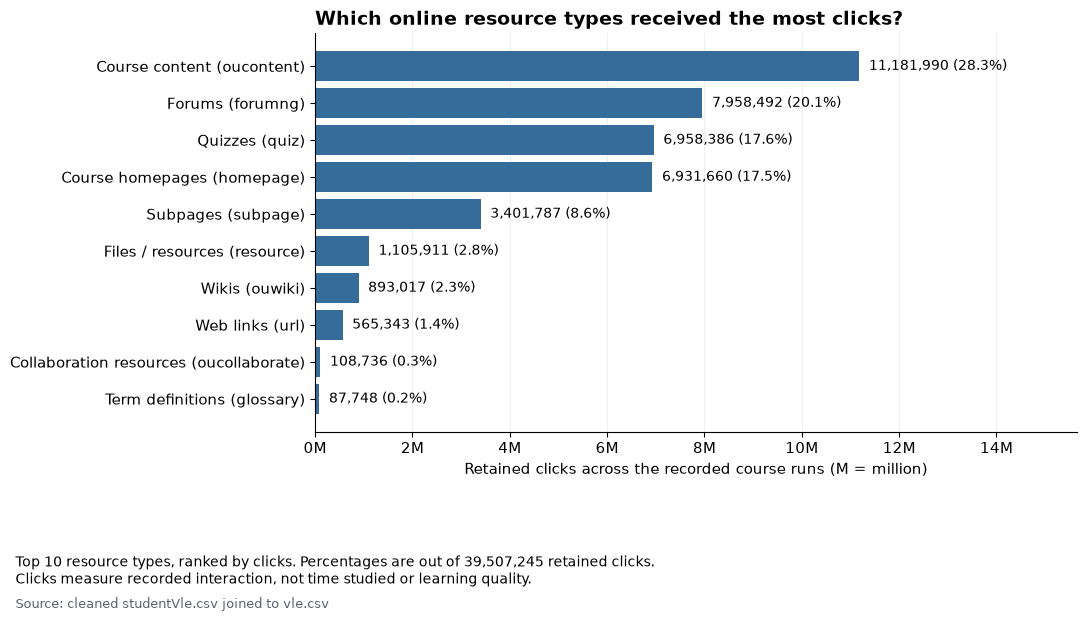

**What we learned:** the most available resource type is **Files / resources (resource)** with **2,660 resources**, but the most-clicked type is **Course content (oucontent)** with **11,181,990 retained clicks. The number of resources offered does not tell us which ones students used most.

In [19]:
top_usage = resource_usage.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(top_usage['Display label'], top_usage['clicks'], color=BLUE)
for bar, (_, row) in zip(bars, top_usage.iterrows()):
    ax.text(bar.get_width() + activity_clicks * .005, bar.get_y() + bar.get_height()/2,
            f"{row['clicks']:,} ({row['Share of retained clicks (%)']:.1f}%)", va='center', fontsize=10)
ax.set_xlim(0, top_usage['clicks'].max() * 1.4)
ax.set_xlabel('Retained clicks across the recorded course runs (M = million)')
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value/1_000_000:g}M'))
ax.set_title('Which online resource types received the most clicks?', loc='left')
ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
chart_note(fig, f'Top 10 resource types, ranked by clicks. Percentages are out of {activity_clicks:,} retained clicks.\nClicks measure recorded interaction, not time studied or learning quality.',
           'cleaned studentVle.csv joined to vle.csv', bottom=.19)
plt.show()
most_offered = resource_counts.idxmax()
most_clicked = resource_usage.iloc[0]
display(Markdown(f"**What we learned:** the most available resource type is **{activity_labels.get(most_offered, most_offered)}** "
                 f"with **{resource_counts.loc[most_offered]:,} resources**, but the most-clicked type is "
                 f"**{most_clicked['Display label']}** with **{most_clicked['clicks']:,} retained clicks. "
                 'The number of resources offered does not tell us which ones students used most.'))

### 9. How does recorded activity differ by final outcome?

**Question:** Did students with different results have different amounts of recorded activity?

We total clicks for each course enrollment. “With activity” counts enrollments with at least one retained activity record. The average and median below use only these active enrollments; an enrollment with no activity is not included in those two statistics.

In [20]:
enrollment_activity = student_info.merge(enrollment_clicks, on=enrollment_keys, how='left', validate='one_to_one')
engagement = enrollment_activity.groupby('final_result').agg(
    enrollments=('id_student', 'size'), active_enrollments=('sum_click', 'count'),
    median_clicks=('sum_click', 'median'), average_clicks=('sum_click', 'mean')
).reindex(outcome_order)
engagement['activity_share'] = engagement['active_enrollments'] / engagement['enrollments'] * 100
engagement_table = engagement.reset_index().rename(columns={'final_result': 'Final course result', 'enrollments': 'All enrollments',
    'active_enrollments': 'Enrollments with activity', 'activity_share': 'With activity (%)',
    'median_clicks': 'Middle clicks per active enrollment', 'average_clicks': 'Average clicks per active enrollment'})
show_table(engagement_table, 'Recorded activity by final course outcome',
           'Coverage uses all enrollments within each outcome. Click averages and medians use only enrollments with retained activity.',
           {'All enrollments': '{:,.0f}', 'Enrollments with activity': '{:,.0f}', 'With activity (%)': lambda value: percent_text(value, 2),
            'Middle clicks per active enrollment': '{:,.1f}', 'Average clicks per active enrollment': '{:,.1f}'})
assert len(enrollment_activity) == len(student_info)
assert enrollment_activity['sum_click'].sum() == activity_clicks

**Recorded activity by final course outcome**

Coverage uses all enrollments within each outcome. Click averages and medians use only enrollments with retained activity.

Final course result,All enrollments,Enrollments with activity,Middle clicks per active enrollment,Average clicks per active enrollment,With activity (%)
Distinction,"3,024","3,024","1,896.0","2,666.8",100.00%
Pass,"12,361","12,358","1,343.0","1,922.3",99.98%
Fail,"7,052","6,678",353.0,688.4,94.70%
Withdrawn,"10,156","6,982",217.0,442.7,68.75%


**How to read this chart:** each bar shows the **median** total clicks among enrollments with activity and that outcome. Median means the middle value when totals are sorted. The label gives the median and how many enrollments were included.

Withdrawn students usually have less time to accumulate clicks. We also excluded clicks after recorded withdrawal. This comparison describes an association; it cannot tell us whether more clicks caused better results.

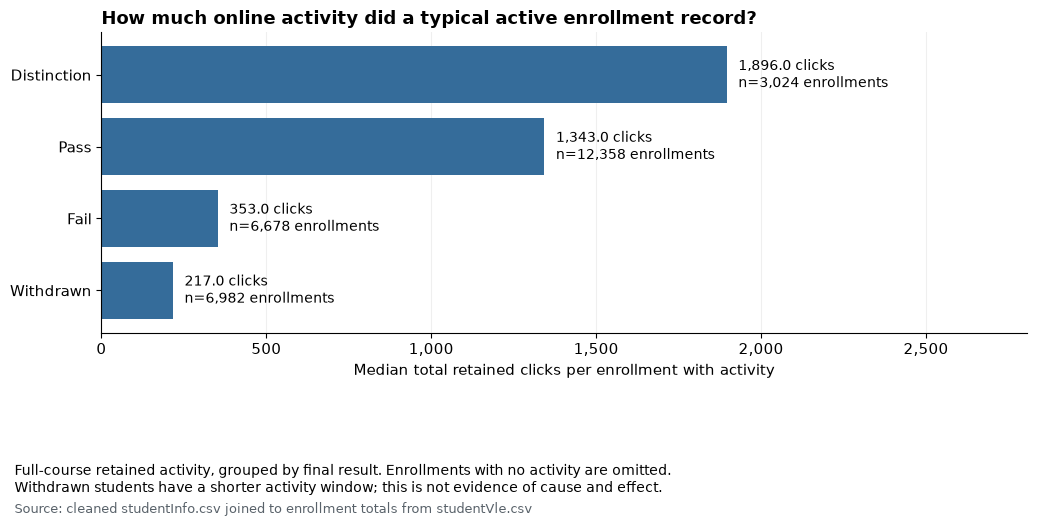

In [21]:
fig, ax = plt.subplots(figsize=(10.5, 5.5))
bars = ax.barh(engagement.index, engagement['median_clicks'], color=BLUE)
ax.invert_yaxis()
for bar, (outcome, row) in zip(bars, engagement.iterrows()):
    ax.text(bar.get_width() + 35, bar.get_y() + bar.get_height()/2,
            f"{row['median_clicks']:,.1f} clicks\nn={row['active_enrollments']:,.0f} enrollments", va='center', fontsize=10)
ax.set_xlim(0, engagement['median_clicks'].max() * 1.48)
ax.set_xlabel('Median total retained clicks per enrollment with activity')
ax.set_title('How much online activity did a typical active enrollment record?', loc='left', fontsize=13)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f'{value:,.0f}'))
ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
chart_note(fig, 'Full-course retained activity, grouped by final result. Enrollments with no activity are omitted.\nWithdrawn students have a shorter activity window; this is not evidence of cause and effect.',
           'cleaned studentInfo.csv joined to enrollment totals from studentVle.csv', bottom=.23)
plt.show()

### 10. What about repeated activity rows?

**Question:** Is one activity row always one independent event?

No. Several rows can refer to the same student, resource, and day. The source has no event ID to prove whether identical lines are accidental copies. They are retained as supplied within the allowed study window.

The daily view combines records into one student/resource/day row. A second click total counts completely matching rows once to show the effect of that choice. It is a sensitivity comparison, not a claim that we recovered the true number of clicks.

In [22]:
vle_audit = manifest['vle_audit']
repetition_metrics = pd.DataFrame({'Measure': ['Usable activity records', 'Distinct student/resource/day groups',
    'Groups with several usable source records', 'Extra records at repeated daily keys', 'Extra completely identical rows'],
    'Count': [vle_audit['clean_rows'], vle_audit['daily_rows'], vle_audit['repeated_daily_groups'],
              vle_audit['extra_rows_at_repeated_daily_keys'], vle_audit['extra_identical_rows']]})
show_table(repetition_metrics, 'Repeated-row checks in the cleaned activity file',
           'These measures overlap; do not add them. Daily groups are not student counts.', {'Count': '{:,.0f}'})
show_table(pd.DataFrame({'Counting rule': ['Sum all retained records', 'Count each completely matching row once'],
                        'Retained click total': [vle_audit['total_clicks_as_supplied'], vle_audit['total_clicks_if_exact_repeats_removed']]}),
           'Click totals under two counting rules',
           'Both use the same cleaned study window. Only the treatment of completely identical rows differs.', {'Retained click total': '{:,.0f}'})

**Repeated-row checks in the cleaned activity file**

These measures overlap; do not add them. Daily groups are not student counts.

Measure,Count
Usable activity records,"10,626,266"
Distinct student/resource/day groups,"8,435,801"
Groups with several usable source records,"1,610,552"
Extra records at repeated daily keys,"2,190,465"
Extra completely identical rows,"785,060"


**Click totals under two counting rules**

Both use the same cleaned study window. Only the treatment of completely identical rows differs.

Counting rule,Retained click total
Sum all retained records,"39,507,245"
Count each completely matching row once,"38,248,299"


## Checks and takeaways

The final cell checks that displayed populations reconcile with the saved cleaned files. It also reports the main findings in plain words using the values calculated above.

In [23]:
assert outcomes['Enrollment count'].sum() == len(student_info)
assert timing_counts['Assessment result records'].sum() == len(student_assessment)
assert activity_partition['Records'].sum() == manifest['vle_audit']['source_rows']
assert activity_summary['clicks'].sum() == activity_clicks
assert by_run_counts.loc[('AAA', '2013J')].sum() == 383
assert validation['passed'].all()
display(Markdown(f'''**What we learned:**

- We have **{unique_students:,} students**, **{len(student_info):,} enrollments**, **{len(student_assessment):,} assessment results**, and **{activity_rows:,} retained activity records**. Those are different units.
- Outcome percentages vary by course run; the denominator is shown in the outcome table.
- Among new results with known usable dates, **{late_share:.1f}% were late**. Average known scores are **{mean_on_time:.2f}/100 on time** versus **{mean_late:.2f}/100 late**.
- Missing deadlines and excluded submission dates are separate reasons for unknown timing. Carried-over marks are shown separately.
- Resource counts are different from actual click counts. A resource can be accessed many times.
- Activity and final outcomes are associated in this dataset. Course differences and shorter withdrawal windows affect that comparison.
- A model will need a prediction date: full-course activity and final outcomes cannot be used as information known earlier. OULAD also lacks a student's personal free-time calendar.

**Validation:** table totals, join populations, activity totals, and the saved cleaning checks reconcile. These checks do not resolve facts missing from the original source.

**Next learning step:** return to section 6 and read the named timing-count table, then the separately titled score table. Their count columns measure different things.
'''))

**What we learned:**

- We have **28,785 students**, **32,593 enrollments**, **173,912 assessment results**, and **10,626,266 retained activity records**. Those are different units.
- Outcome percentages vary by course run; the denominator is shown in the outcome table.
- Among new results with known usable dates, **29.1% were late**. Average known scores are **76.37/100 on time** versus **75.08/100 late**.
- Missing deadlines and excluded submission dates are separate reasons for unknown timing. Carried-over marks are shown separately.
- Resource counts are different from actual click counts. A resource can be accessed many times.
- Activity and final outcomes are associated in this dataset. Course differences and shorter withdrawal windows affect that comparison.
- A model will need a prediction date: full-course activity and final outcomes cannot be used as information known earlier. OULAD also lacks a student's personal free-time calendar.

**Validation:** table totals, join populations, activity totals, and the saved cleaning checks reconcile. These checks do not resolve facts missing from the original source.

**Next learning step:** return to section 6 and read the named timing-count table, then the separately titled score table. Their count columns measure different things.
